<a href="https://colab.research.google.com/github/anshiikaa18/vehicle-service-predictor/blob/main/01_eda_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [57]:
from google.colab import files
up=files.upload()

Saving engine_data.csv to engine_data (1).csv


In [58]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("engine_data.csv")
df.head()


,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
0,700,2.493592,11.790927,3.178981,84.144163,81.632187,1
1,876,2.941606,16.193866,2.464504,77.640934,82.445724,0
2,520,2.961746,6.553147,1.064347,77.752266,79.645777,1
3,473,3.707835,19.510172,3.727455,74.129907,71.774629,1
4,619,5.672919,15.738871,2.052251,78.396989,87.000225,0


In [59]:
df.shape

(19535, 7)

rows and columns

In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19535 entries, 0 to 19534
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Engine rpm        19535 non-null  int64  
 1   Lub oil pressure  19535 non-null  float64
 2   Fuel pressure     19535 non-null  float64
 3   Coolant pressure  19535 non-null  float64
 4   lub oil temp      19535 non-null  float64
 5   Coolant temp      19535 non-null  float64
 6   Engine Condition  19535 non-null  int64  
dtypes: float64(5), int64(2)
memory usage: 1.0 MB


summary ,column data

In [61]:
df.describe()

,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
count,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000
mean,791.239263,3.303775,6.655615,2.335369,77.643420,78.427433,0.630509
std,267.611193,1.021643,2.761021,1.036382,3.110984,6.206749,0.482679
min,61.000000,0.003384,0.003187,0.002483,71.321974,61.673325,0.000000
25%,593.000000,2.518815,4.916886,1.600466,75.725990,73.895421,0.000000
50%,746.000000,3.162035,6.201720,2.166883,76.817350,78.346662,1.000000
75%,934.000000,4.055272,7.744973,2.848840,78.071691,82.915411,1.000000
max,2239.000000,7.265566,21.138326,7.478505,89.580796,195.527912,1.000000


returns count mean std  miin

In [62]:
df.isnull().sum()

,0
Engine rpm,0
Lub oil pressure,0
Fuel pressure,0
Coolant pressure,0
lub oil temp,0
Coolant temp,0
Engine Condition,0


returns total null value

In [64]:
df.duplicated().sum()

np.int64(0)

**CLEANING THE DATA**

In [65]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
df.columns.tolist()

['engine_rpm',
 'lub_oil_pressure',
 'fuel_pressure',
 'coolant_pressure',
 'lub_oil_temp',
 'coolant_temp',
 'engine_condition']

In [66]:
df = df.drop_duplicates()
df["engine_condition"].value_counts(normalize=True)

,proportion
engine_condition,
1,0.630509
0,0.369491


**OUTLIERS**

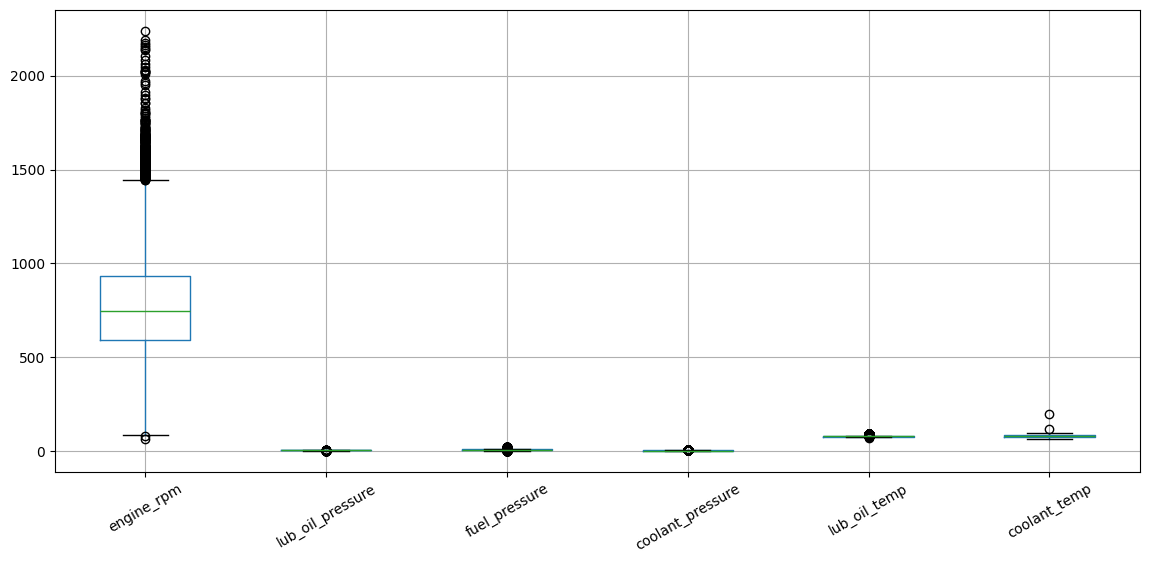

In [67]:
features = df.columns[:-1]
plt.figure(figsize=(14, 6))
df[features].boxplot()
plt.xticks(rotation=30)
plt.show()

In [68]:
for col in features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum()
    print(col, n)

engine_rpm 464
lub_oil_pressure 66
fuel_pressure 1135
coolant_pressure 785
lub_oil_temp 2617
coolant_temp 2


**EDA CHARTS**

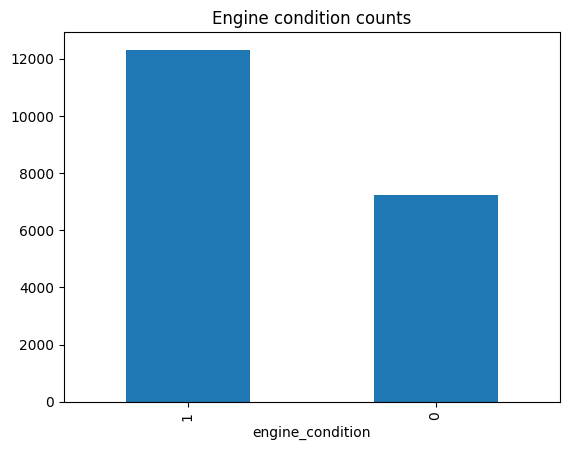

In [69]:
# Q1: How balanced is the target?
df["engine_condition"].value_counts().plot(kind="bar")
plt.title("Engine condition counts")
plt.show()

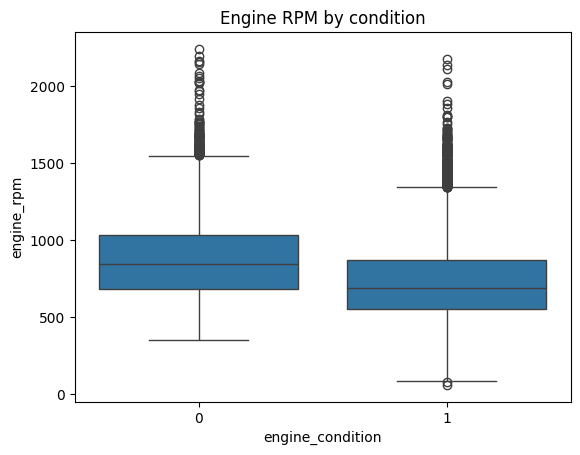

In [70]:
# Q2: How does RPM differ by condition?
sns.boxplot(x="engine_condition", y="engine_rpm", data=df)
plt.title("Engine RPM by condition")
plt.show()

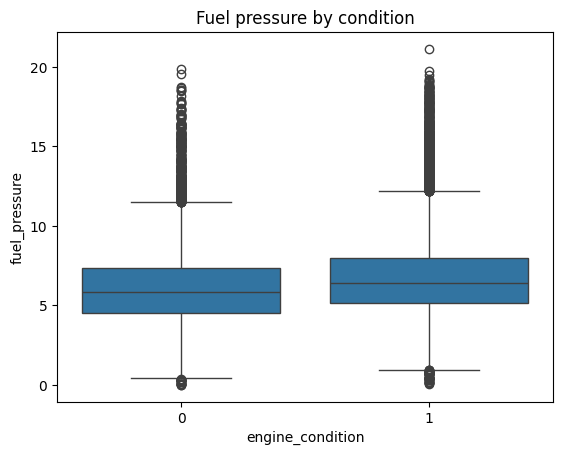

In [71]:
# Q3: Fuel pressure by condition
sns.boxplot(x="engine_condition", y="fuel_pressure", data=df)
plt.title("Fuel pressure by condition")
plt.show()

In [72]:
# Q4: Average of each sensor by condition
df.groupby("engine_condition").mean().round(1)

,engine_rpm,lub_oil_pressure,fuel_pressure,coolant_pressure,lub_oil_temp,coolant_temp
engine_condition,,,,,,
0,885.0,3.2,6.2,2.4,78.0,78.8
1,736.3,3.4,6.9,2.3,77.4,78.2


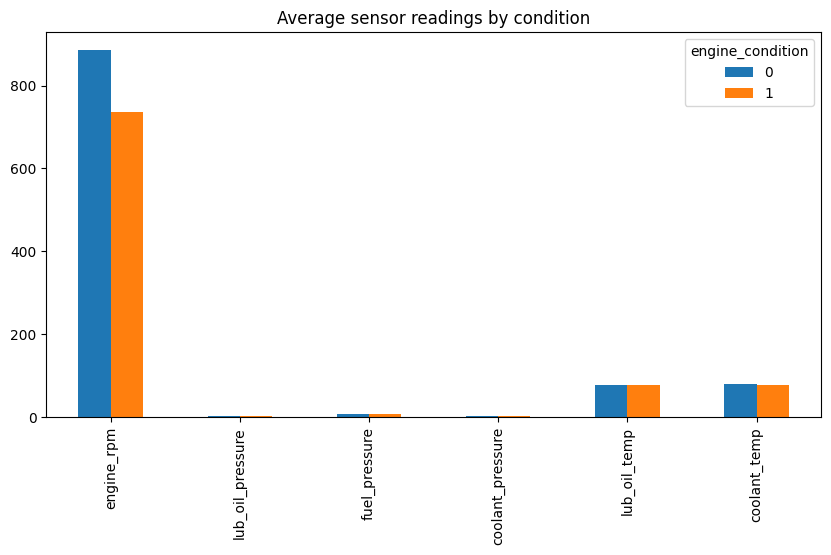

In [73]:
df.groupby("engine_condition").mean().T.plot(kind="bar", figsize=(10, 5))
plt.title("Average sensor readings by condition")
plt.show()

**CORELATION AND SAVE**

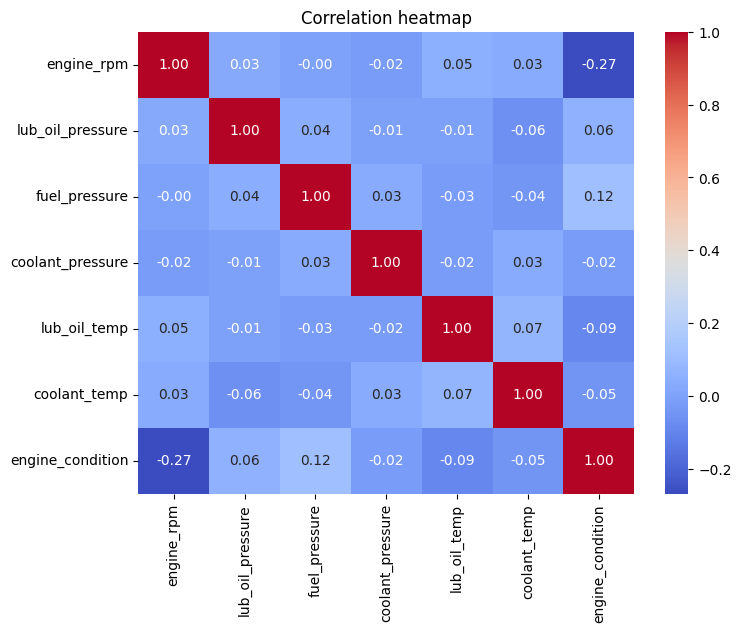

In [74]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

In [76]:
df.to_csv("cleaned_engine_data.csv", index=False)